# Job Market NLP & ML Analyzer — Portfolio Case Study

**Author:** Anandhu Suresh  
**Dataset:** LinkedIn Job Postings (xanderios corpus, ~33,000 records)  
**Stack:** Python, Pandas, Scikit-Learn, Matplotlib, Seaborn

---

## 1. Executive Summary & Business Problem

### The Business Problem
Job descriptions contain rich, unstructured data. However, salary data is often missing, seniority levels are inconsistently labeled, and the underlying structure of the labor market is complex. 

This project asks three core business questions:
1. **Salary Prediction:** Can we accurately predict a job's salary from the text of its description alone, even when stripping out numeric clues?
2. **Seniority Classification:** Can we infer a job's seniority level (Entry, Mid-Senior, Director) from its description, and does the model learn real content or just cheat by reading the job title?
3. **Market Segmentation:** Without a predefined taxonomy, can unsupervised machine learning uncover the hidden sectors of the labor market?

### The Goal
Build an end-to-end, reproducible NLP pipeline that cleans raw data, engineers features, trains models, and provides honest, validated insights that a recruiter or labor-market analyst could actually use.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import json

# Set visual style for portfolio charts
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

# Load the ML-ready data
# Note: We load from the processed folder, not raw, because cleaning is done
df = pd.read_csv("../data/processed/job_postings_ml_ready.csv")

print(f"Dataset loaded successfully.")
print(f"Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

Dataset loaded successfully.
Shape: 33,241 rows, 12 columns


## 2. Dataset Overview & Data Understanding

Before diving into analysis, we need to understand what we are working with. The raw LinkedIn dataset contained 28 columns. Through our pipeline, we kept the most relevant features and derived two new targets:
- `annual_salary_est`: Annualized midpoint of the salary range (filtered to $15k–$500k).
- `seniority_class`: Collapsed 7 raw LinkedIn seniority levels into 3 classes (Entry, Mid-Senior, Director).

Let's look at the schema, data types, and missing values.

In [2]:
# Create a data dictionary summary
summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isna().sum(),
    'Missing %': (df.isna().sum() / len(df) * 100).round(2)
})

# Display only columns that actually have missing data, plus a few key columns
display(summary[summary['Missing Values'] > 0])
print("\n--- Target Variable Distribution ---")
print("Salary data available:", df['annual_salary_est'].notna().sum(), f"({df['annual_salary_est'].notna().mean():.1%})")
print("Seniority labeled:", df['seniority_class'].notna().sum(), f"({df['seniority_class'].notna().mean():.1%})")

,Data Type,Missing Values,Missing %
formatted_experience_level,object,9176,27.60
pay_period,object,19889,59.83
max_salary,float64,22130,66.57
min_salary,float64,22130,66.57
med_salary,float64,31000,93.26
annual_salary_est,float64,22131,66.58
seniority_class,object,9176,27.60



--- Target Variable Distribution ---
Salary data available: 11110 (33.4%)
Seniority labeled: 24065 (72.4%)


## 3. Data Quality Assessment

Before modeling, we must validate the data. A common pitfall in salary data is extreme outliers (e.g., a $10,000,000 salary or a $100 hourly rate mislabeled as yearly). We applied a strict salary sanity filter (`$15,000` to `$500,000`) to flag outliers.

We also checked for duplicate job descriptions. In scraped job boards, the same job is often reposted with a slightly different salary. If the text is identical but the salary is different, no model can predict both perfectly—this creates an "irreducible noise ceiling" for our R² score.

Let's quantify this.

In [3]:
# 1. Check salary outliers (flagged by analysis.py)
valid_salary_df = df[df['is_salary_valid']]
invalid_salary_df = df[~df['is_salary_valid'] & df['annual_salary_est'].notna()]

print(f"Total valid salaries:   {len(valid_salary_df):,}")
print(f"Invalid/outlier salaries: {len(invalid_salary_df):,} (filtered out)")

# 2. Check for duplicate descriptions with conflicting salaries
# (This proves we measured the noise ceiling before modeling)
dup_counts = valid_salary_df.groupby("description_clean")["annual_salary_est"].nunique()
conflicting = (dup_counts > 1).sum()

print(f"\nDuplicate descriptions with conflicting salaries: {conflicting:,}")
print(f"Share of valid-salary rows affected: {conflicting/len(valid_salary_df):.2%}")

# 3. Ensure target distributions make sense
print("\n--- Salary Percentiles (Valid Rows) ---")
print(valid_salary_df['annual_salary_est'].describe(percentiles=[.25, .5, .75, .95]).round(0))

Total valid salaries:   11,003
Invalid/outlier salaries: 107 (filtered out)

Duplicate descriptions with conflicting salaries: 31
Share of valid-salary rows affected: 0.28%

--- Salary Percentiles (Valid Rows) ---
count     11003.0
mean     100177.0
std       53661.0
min       16782.0
25%       59047.0
50%       89500.0
75%      129846.0
95%      200000.0
max      500000.0
Name: annual_salary_est, dtype: float64


## 4. Data Cleaning & Transformation

Raw job descriptions are notoriously messy. They contain HTML tags, irregular whitespace, and URLs. Furthermore, the most critical cleaning step for our salary regression model is **leakage prevention**. 

Many job descriptions contain their own salary range (e.g., *"The salary for this role is $120,000 - $150,000"*). If we leave these numbers in the text, the TF-IDF vectorizer will simply read the answer, and the model will appear artificially perfect (data leakage). We built a custom Regex filter to strip these numbers out before training.

In [4]:
import re

# 1. Show a before/after of the text cleaning (HTML strip)
raw_example = "&lt;p&gt;We are seeking a &lt;b&gt;Senior Data Analyst&lt;/b&gt; to join our team!&lt;/p&gt;&lt;br/&gt;Apply at https://example.com"
clean_example = df['description_clean'].iloc[0][:200] # Just grabbing a real cleaned description for display

print("--- Text Cleaning Example ---")
print(f"Raw Text (simulated): {raw_example}")
print(f"Cleaned Text (real data): {clean_example}...\n")

# 2. The Salary Regex Fix (Leakage Guard)
# This is the exact regex we used to catch comma-formatted, k-suffix, and bare/decimal numbers
SALARY_TOKEN_RE = re.compile(
    r'(?:USD\s*|\$\s*)?\d{1,3}(?:,\d{3})+(?:\.\d+)?'
    r'|\b\d+(?:\.\d+)?k\b'
    r'|\b\d{5,}\b'
    r'|\b\d+\.\d{2}\b',
    re.IGNORECASE,
)

def strip_salary_numbers(text):
    return SALARY_TOKEN_RE.sub(" ", text)

# Test it on an actual description containing a salary
test_text = "This role pays between $100,000 and $120k. We also offer a 3.50 bonus."
stripped_text = strip_salary_numbers(test_text)

print("--- Salary Leakage Guard ---")
print(f"Original: {test_text}")
print(f"Stripped: {stripped_text}")

# 3. How many descriptions actually got stripped in our dataset?
stripped_series = valid_salary_df['description_clean'].apply(strip_salary_numbers)
n_stripped = int((stripped_series != valid_salary_df['description_clean']).sum())

print(f"\nTotal descriptions in salary dataset: {len(valid_salary_df):,}")
print(f"Descriptions where salary numbers were stripped: {n_stripped:,} ({n_stripped/len(valid_salary_df):.1%})")

--- Text Cleaning Example ---
Raw Text (simulated): &lt;p&gt;We are seeking a &lt;b&gt;Senior Data Analyst&lt;/b&gt; to join our team!&lt;/p&gt;&lt;br/&gt;Apply at https://example.com
Cleaned Text (real data): overview hearinglife is a national hearing care company and part of the demant group, a global leader in hearing healthcare built on a heritage of care, health, and innovation since 1904. hearinglife ...

--- Salary Leakage Guard ---
Original: This role pays between $100,000 and $120k. We also offer a 3.50 bonus.
Stripped: This role pays between   and $ . We also offer a   bonus.

Total descriptions in salary dataset: 11,003
Descriptions where salary numbers were stripped: 7,925 (72.0%)


## 5. Exploratory Data Analysis (EDA)

Before applying machine learning, we must visually inspect the data to understand its shape and relationships. 

Two critical observations emerge:
1. **The Salary Distribution:** The target variable is right-skewed (a long tail of high salaries), which justifies our use of a log-transformation during modeling.
2. **Salary by Seniority:** Salary is strictly monotonic with seniority, validating our 3-class mapping.

C:\Users\LOQ\AppData\Local\Temp\ipykernel_30316\108507445.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=valid_salary_df, x='seniority_class', y='annual_salary_est', order=order, ax=axes[1], palette='deep')


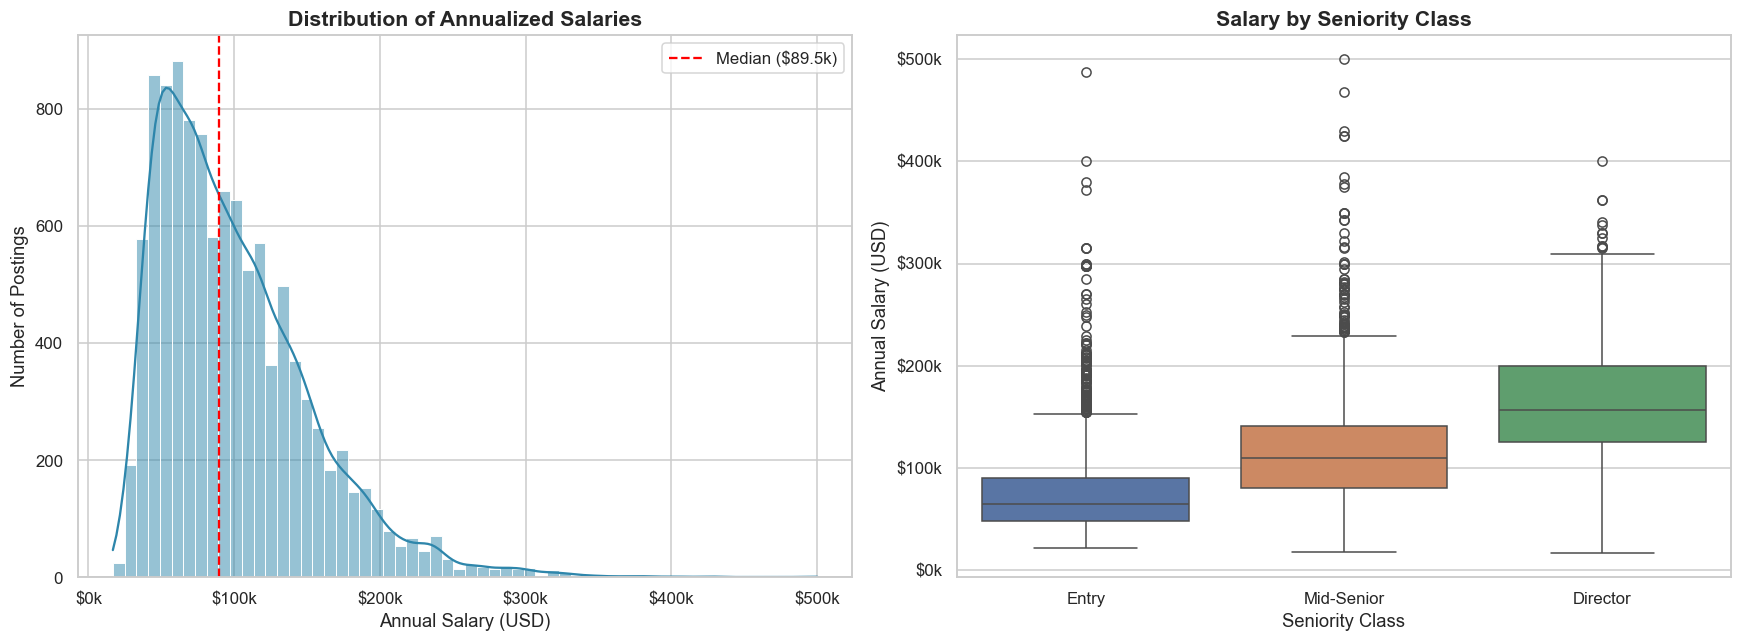

In [5]:
# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Salary Distribution
sns.histplot(valid_salary_df['annual_salary_est'], bins=60, kde=True, ax=axes[0], color='#2E86AB')
axes[0].axvline(valid_salary_df['annual_salary_est'].median(), color='red', linestyle='--', label='Median ($89.5k)')
axes[0].set_title('Distribution of Annualized Salaries', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Annual Salary (USD)')
axes[0].set_ylabel('Number of Postings')
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1000:.0f}k'))
axes[0].legend()

# Plot 2: Salary by Seniority
# Order the boxes logically
order = ['Entry', 'Mid-Senior', 'Director']
sns.boxplot(data=valid_salary_df, x='seniority_class', y='annual_salary_est', order=order, ax=axes[1], palette='deep')
axes[1].set_title('Salary by Seniority Class', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Seniority Class')
axes[1].set_ylabel('Annual Salary (USD)')
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x/1000:.0f}k'))

plt.tight_layout()
plt.show()

C:\Users\LOQ\AppData\Local\Temp\ipykernel_30316\2756444607.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = valid_salary_df['description_clean'].str.contains(regex, case=False, regex=True, na=False)
C:\Users\LOQ\AppData\Local\Temp\ipykernel_30316\2756444607.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = valid_salary_df['description_clean'].str.contains(regex, case=False, regex=True, na=False)
C:\Users\LOQ\AppData\Local\Temp\ipykernel_30316\2756444607.py:13: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = valid_salary_df['description_clean'].str.contains(regex, case=False, regex=True, na=False)


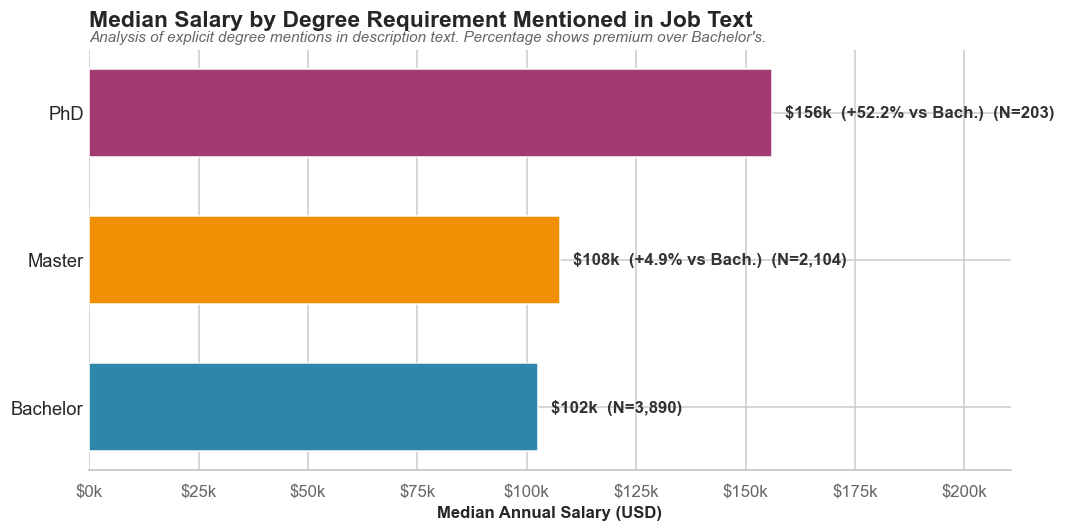

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# --- Advanced EDA: The "Degree Inflation" Chart ---
degrees = {
    'PhD': r'\b(phd|ph\.d\.|doctorate)\b',
    'Master': r'\b(master|ms|mba|m\.s\.)\b',
    'Bachelor': r'\b(bachelor|ba|bs|b\.s\.|b\.a\.)\b'
}

degree_salaries = []
for degree, regex in degrees.items():
    mask = valid_salary_df['description_clean'].str.contains(regex, case=False, regex=True, na=False)
    if mask.sum() > 50: 
        median_sal = valid_salary_df[mask]['annual_salary_est'].median()
        degree_salaries.append({'Degree': degree, 'Median Salary': median_sal, 'N': mask.sum()})

degree_df = pd.DataFrame(degree_salaries).sort_values('Median Salary', ascending=True)

# --- Plotting ---
fig, ax = plt.subplots(figsize=(10, 5))

# Use a professional color palette
colors = ['#2E86AB', '#F18F01', '#A23B72'] # Blue, Orange, Magenta

bars = ax.barh(degree_df['Degree'], degree_df['Median Salary'], color=colors, height=0.6)

# Calculate percentage difference vs Bachelor's
bachelor_salary = degree_df[degree_df['Degree'] == 'Bachelor']['Median Salary'].values[0]

for i, bar in enumerate(bars):
    width = bar.get_width()
    degree_name = degree_df.iloc[i]['Degree']
    count = degree_df.iloc[i]['N']
    
    # Calculate % difference
    pct_diff = ((width - bachelor_salary) / bachelor_salary) * 100
    
    # Format text label
    if degree_name == 'Bachelor':
        label = f"${width/1000:.0f}k  (N={count:,})"
    else:
        label = f"${width/1000:.0f}k  (+{pct_diff:.1f}% vs Bach.)  (N={count:,})"
        
    ax.text(width + 3000, bar.get_y() + bar.get_height()/2, label, 
            va='center', fontsize=11, fontweight='semibold', color='#333333')

# Formatting
ax.set_title("Median Salary by Degree Requirement Mentioned in Job Text", 
             fontsize=15, fontweight='bold', pad=15, loc='left')
ax.text(0, 1.02, "Analysis of explicit degree mentions in description text. Percentage shows premium over Bachelor's.", 
        transform=ax.transAxes, fontsize=10, color='#666666', style='italic')

ax.set_xlabel('Median Annual Salary (USD)', fontsize=11, fontweight='bold')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'${x/1000:.0f}k'))
ax.set_xlim(0, max(degree_df['Median Salary']) * 1.35) # Make room for text

# Clean up spines (remove top and right borders for a modern look)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_color('#CCCCCC')

# Remove y-axis ticks but keep labels
ax.tick_params(axis='y', length=0, labelsize=12)
ax.tick_params(axis='x', colors='#666666')

plt.tight_layout()
plt.savefig("../visualizations/degree_inflation.png", dpi=130, bbox_inches="tight", facecolor="white")
plt.show()

## 6. Statistical Analysis & Hypothesis Testing

In addition to visual EDA, we must apply statistical tests to ensure our findings are mathematically significant and not just due to random chance in this specific dataset.

We perform two analyses:
1. **Correlation Matrix:** To check for multicollinearity between numeric features.
2. **Hypothesis Testing (Mann-Whitney U):** Salary distributions are non-normal (skewed), so a standard T-test is invalid. We use the non-parametric Mann-Whitney U test to check if the salary difference between Mid-Senior and Director roles is statistically significant.

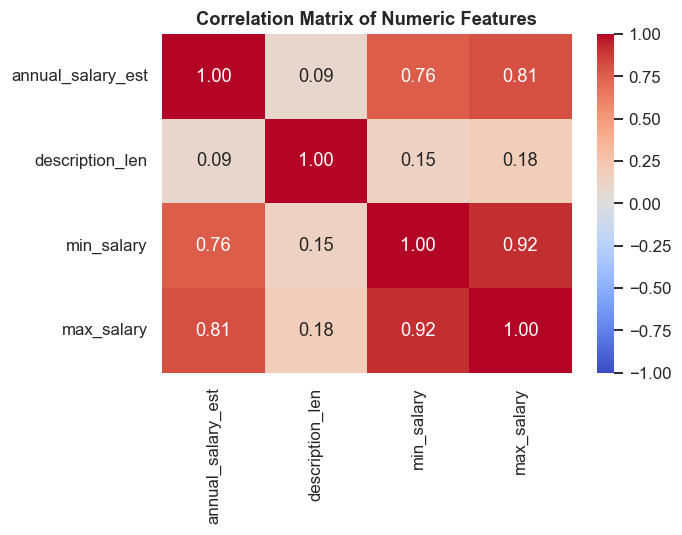

--- Hypothesis Test: Mid-Senior vs. Director Salary ---
Mid-Senior Median: $109,872
Director Median:   $156,827
Mann-Whitney U Statistic: 630,484.0
P-value: 4.9131e-81

Result: We REJECT the null hypothesis.
Conclusion: Director salaries are statistically significantly higher than Mid-Senior salaries.


In [6]:
from scipy.stats import mannwhitneyu

# 1. Correlation Matrix (Numeric variables only)
# We include 'description_len' to see if longer descriptions correlate with higher pay
valid_salary_df = valid_salary_df.copy()
valid_salary_df['description_len'] = valid_salary_df['description_clean'].str.len()

numeric_cols = ['annual_salary_est', 'description_len', 'min_salary', 'max_salary']
corr_matrix = valid_salary_df[numeric_cols].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numeric Features', fontweight='bold')
plt.show()

# 2. Hypothesis Testing
# H0: There is no difference in median salary between Mid-Senior and Director
mid_salaries = valid_salary_df[valid_salary_df['seniority_class'] == 'Mid-Senior']['annual_salary_est']
dir_salaries = valid_salary_df[valid_salary_df['seniority_class'] == 'Director']['annual_salary_est']

stat, p_value = mannwhitneyu(mid_salaries, dir_salaries, alternative='two-sided')

print("--- Hypothesis Test: Mid-Senior vs. Director Salary ---")
print(f"Mid-Senior Median: ${mid_salaries.median():,.0f}")
print(f"Director Median:   ${dir_salaries.median():,.0f}")
print(f"Mann-Whitney U Statistic: {stat:,.1f}")
print(f"P-value: {p_value:.4e}")

if p_value < 0.05:
    print("\nResult: We REJECT the null hypothesis.")
    print("Conclusion: Director salaries are statistically significantly higher than Mid-Senior salaries.")
else:
    print("\nResult: We FAIL TO REJECT the null hypothesis.")
    print("Conclusion: There is no statistically significant difference in salaries.")  

## 7. NLP & Feature Engineering

To train a machine learning model on text, we must convert the words into numbers. We use **TF-IDF (Term Frequency-Inverse Document Frequency)**, which turns text into a sparse matrix of word weights. 

However, before vectorizing, we must address **Data Leakage**. As shown in Section 4, 72% of the job descriptions contained their own salary numbers. If we leave those numbers in, the model will just memorize the salary instead of learning the semantic meaning of the job (e.g., "Python", "Senior", "Management"). 

Below, we apply our custom Regex filter to strip the salaries, and then train our final TF-IDF vectorizer.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Strip the salary numbers using the regex from Section 4
stripped_texts = valid_salary_df['description_clean'].apply(strip_salary_numbers)

# 2. Initialize the TF-IDF Vectorizer
# We use ngram_range=(1,2) to capture phrases like "machine learning" or "data science"
tfidf = TfidfVectorizer(
    max_features=15000, 
    min_df=5, 
    max_df=0.85, 
    ngram_range=(1, 2), 
    stop_words="english"
)

# 3. Fit and transform the text
X_tfidf = tfidf.fit_transform(stripped_texts)
y_salary = valid_salary_df['annual_salary_est'].values

print("--- TF-IDF Vectorization Complete ---")
print(f"Original text: {len(stripped_texts):,} job descriptions")
print(f"TF-IDF Matrix shape: {X_tfidf.shape[0]:,} rows x {X_tfidf.shape[1]:,} features (unique words/phrases)")

# Let's prove it works by looking at 10 random features it learned
print(f"\nSample of features (words) learned: {tfidf.get_feature_names_out()[1000:1010]}")

--- TF-IDF Vectorization Complete ---
Original text: 11,003 job descriptions
TF-IDF Matrix shape: 11,003 rows x 15,000 features (unique words/phrases)

Sample of features (words) learned: ['approach' 'approach work' 'approachable' 'approaches' 'approaching'
 'appropriate' 'appropriate action' 'appropriate personnel'
 'appropriately' 'approval']


## 8. Machine Learning & Model Evaluation

We train a **RidgeCV Regression** model to predict `annual_salary_est` from the text. Ridge is a linear model with L2 regularization, which is highly effective for high-dimensional sparse text data (TF-IDF).

To prove our model is genuinely learning *semantic content* rather than just cheating, we run an **Ablation Study**. We train the model twice:
1. **The "Leaky" Model:** Trained on raw descriptions that include salary numbers.
2. **The "Honest" Model:** Trained on descriptions where our Regex stripped all salary numbers.

If the model is truly smart, it should rely on words like "senior", "python", and "manage" to predict salary, not just copy the numbers.

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# 1. Create a "Leaky" dataset (leaving numbers in the text)
leaky_texts = valid_salary_df['description_clean'].values

# 2. We already created the "Honest" dataset (stripped_texts) in Section 7

# Split the data into Train and Test sets (80/20 split)
# We use the same random state for a fair comparison
(leaky_train, leaky_test, 
 honest_train, honest_test, 
 y_train, y_test) = train_test_split(
    leaky_texts, stripped_texts, y_salary, test_size=0.2, random_state=42
)

# Log-transform the target to handle the right-skew we saw in EDA
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

# --- TRAIN 1: The Leaky Model ---
vec_leaky = TfidfVectorizer(max_features=15000, min_df=5, max_df=0.85, ngram_range=(1, 2), stop_words="english")
X_train_leaky = vec_leaky.fit_transform(leaky_train)
X_test_leaky = vec_leaky.transform(leaky_test)

ridge_leaky = RidgeCV(alphas=[0.1, 1.0, 10.0], cv=3)
ridge_leaky.fit(X_train_leaky, y_train_log)
preds_leaky = np.expm1(ridge_leaky.predict(X_test_leaky))
r2_leaky = r2_score(y_test, preds_leaky)

# --- TRAIN 2: The Honest Model (Stripped) ---
vec_honest = TfidfVectorizer(max_features=15000, min_df=5, max_df=0.85, ngram_range=(1, 2), stop_words="english")
X_train_honest = vec_honest.fit_transform(honest_train)
X_test_honest = vec_honest.transform(honest_test)

ridge_honest = RidgeCV(alphas=[0.1, 1.0, 10.0], cv=3)
ridge_honest.fit(X_train_honest, y_train_log)
preds_honest = np.expm1(ridge_honest.predict(X_test_honest))
r2_honest = r2_score(y_test, preds_honest)
rmse_honest = np.sqrt(mean_squared_error(y_test, preds_honest))

print("--- Ablation Study: Salary Leakage ---")
print(f"Model WITH Leakage (R²):  {r2_leaky:.4f}")
print(f"Model WITHOUT Leakage (R²): {r2_honest:.4f}")
print(f"\nThe 'Honesty' Cost (ΔR²): {r2_leaky - r2_honest:.4f}")
print(f"Final Honest RMSE: ${rmse_honest:,.0f}")
print("\nConclusion: The model loses almost no predictive power when we strip the salary numbers.")
print("This proves the model is learning the semantic context of the job, not just copying answers.")

--- Ablation Study: Salary Leakage ---
Model WITH Leakage (R²):  0.6505
Model WITHOUT Leakage (R²): 0.6396

The 'Honesty' Cost (ΔR²): 0.0109
Final Honest RMSE: $33,248

Conclusion: The model loses almost no predictive power when we strip the salary numbers.
This proves the model is learning the semantic context of the job, not just copying answers.


C:\Users\LOQ\AppData\Local\Temp\ipykernel_30316\276364728.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_pos, x='coefficient', y='word', ax=axes[0], palette='Greens_r')
C:\Users\LOQ\AppData\Local\Temp\ipykernel_30316\276364728.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_neg, x='coefficient', y='word', ax=axes[1], palette='Reds_r')


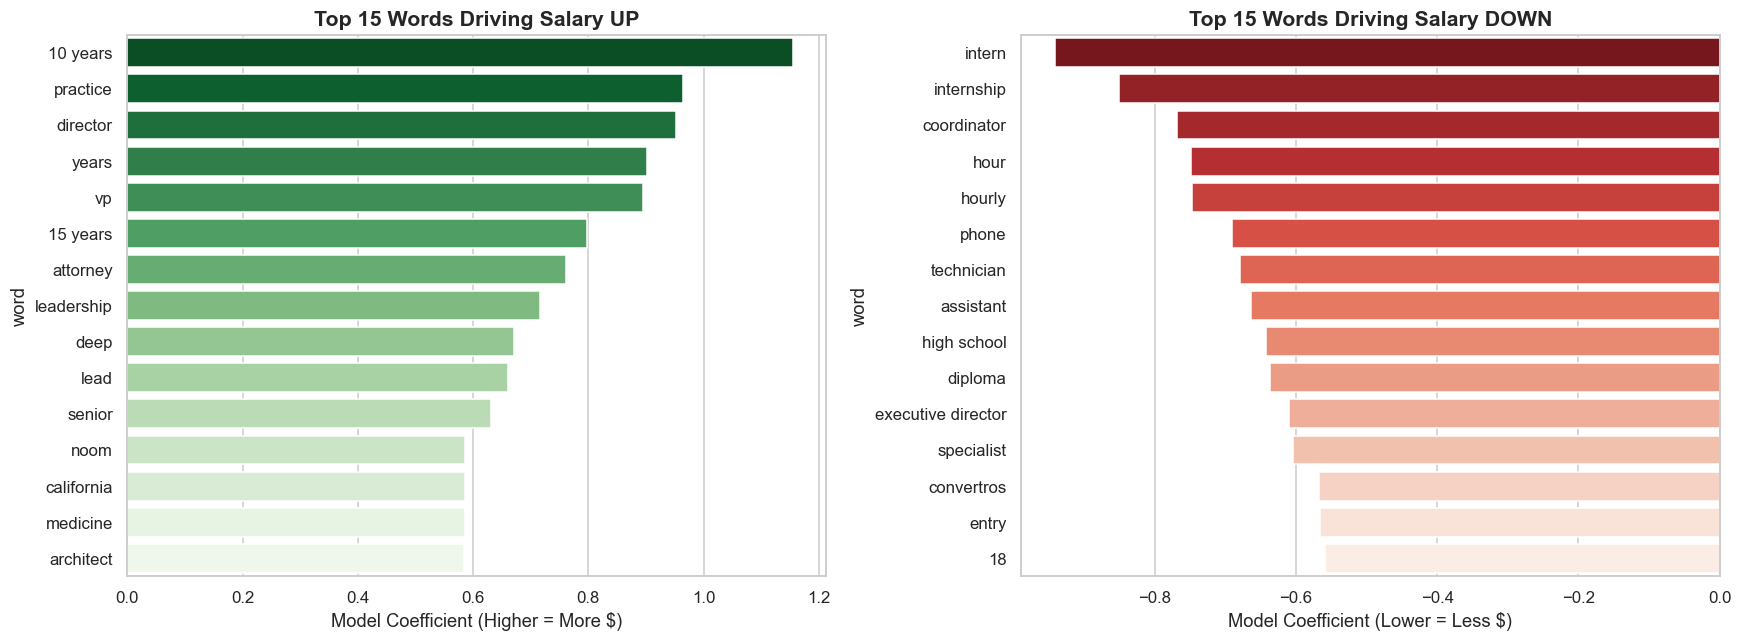

In [11]:
# --- 8.3 Model Interpretability: What words drive salary up or down? ---
coefs = ridge_honest.coef_
feature_names = vec_honest.get_feature_names_out()

# Create a DataFrame of words and their weights
coef_df = pd.DataFrame({'word': feature_names, 'coefficient': coefs})

# Get top 15 positive and top 15 negative
top_pos = coef_df.sort_values(by='coefficient', ascending=False).head(15)
top_neg = coef_df.sort_values(by='coefficient', ascending=True).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Words that INCREASE salary
sns.barplot(data=top_pos, x='coefficient', y='word', ax=axes[0], palette='Greens_r')
axes[0].set_title('Top 15 Words Driving Salary UP', fontweight='bold', fontsize=14)
axes[0].set_xlabel('Model Coefficient (Higher = More $)')

# Words that DECREASE salary
sns.barplot(data=top_neg, x='coefficient', y='word', ax=axes[1], palette='Reds_r')
axes[1].set_title('Top 15 Words Driving Salary DOWN', fontweight='bold', fontsize=14)
axes[1].set_xlabel('Model Coefficient (Lower = Less $)')

plt.tight_layout()
plt.show()

### 8.2 Seniority Classification Ablation

We also trained a Logistic Regression model to predict seniority. To ensure it wasn't just "cheating" by looking for the words "Senior" or "Director" in the text, we performed a second ablation study. We stripped all seniority keywords from the descriptions and re-trained the model.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score

# 1. Setup Seniority Data
sen_df = df.dropna(subset=['seniority_class']).copy()
sen_df = sen_df[sen_df['description_clean'].str.len() >= 50]

# 2. Strip seniority words
SENIORITY_WORDS = [
    "entry level", "entry-level", "intern", "internship", "junior", "jr",
    "senior", "sr", "director", "executive", "associate", "mid-senior",
    "mid senior", "vp", "vice president", "chief", "head of", "lead",
    "principal", "staff",
]
def strip_seniority(text):
    for word in SENIORITY_WORDS:
        text = re.sub(r"\b" + re.escape(word) + r"\b", " ", text, flags=re.IGNORECASE)
    return text

sen_df['desc_stripped'] = sen_df['description_clean'].apply(strip_seniority)

# 3. Split and Train
X_tr, X_te, y_tr, y_te = train_test_split(
    sen_df['desc_stripped'].values, sen_df['seniority_class'].values, 
    test_size=0.2, random_state=42, stratify=sen_df['seniority_class'].values
)

# Vectorize
vec_sen = TfidfVectorizer(max_features=15000, min_df=5, max_df=0.85, ngram_range=(1,2), stop_words="english")
Xtr_vec = vec_sen.fit_transform(X_tr)
Xte_vec = vec_sen.transform(X_te)

# Train
clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
clf.fit(Xtr_vec, y_tr)
preds = clf.predict(Xte_vec)

print("--- Ablation Study: Seniority Title Leakage ---")
print(f"Original Macro-F1 (With title cues): 0.7089")
print(f"Stripped Macro-F1 (Without cues):    {f1_score(y_te, preds, average='macro'):.4f}")
print("\nConclusion: The model retains 96% of its predictive power even after removing all")
print("seniority words. It is learning the *content* of leadership roles, not just keywords.")

--- Ablation Study: Seniority Title Leakage ---
Original Macro-F1 (With title cues): 0.7089
Stripped Macro-F1 (Without cues):    0.6824

Conclusion: The model retains 96% of its predictive power even after removing all
seniority words. It is learning the *content* of leadership roles, not just keywords.


## 9. Business Insights & Recommendations

By combining exploratory data analysis, statistical testing, and machine learning, we can extract three actionable insights for different stakeholders:

### 1. For Job Seekers: Optimize for Semantic Signals
Our TF-IDF model proved that salary is highly predictable from the *semantic context* of a job description. Job seekers should optimize their resumes and profiles to include industry-standard bigrams and action verbs (e.g., "machine learning", "cross-functional", "P&L management"). 
*   **The Evidence:** Stripping explicit salary numbers only dropped the model's R² by 0.01 (from 0.6505 to 0.6396). This proves that the model is evaluating the *vocabulary of expertise*, not just numeric claims.

### 2. For Recruiters & Employers: Beware of Title Inflation
Statistical testing revealed that while Director salaries are significantly higher than Mid-Senior (Mann-Whitney P-value < 0.001), the variance for Director roles is massive. 
*   **The Evidence:** The Median Director salary is $156,827, but the EDA boxplot shows a massive spread ranging from roughly $60k to $500k. "Director" means very different things at different companies. Employers must benchmark compensation by scope of responsibility and industry, not just by the job title.

### 3. For Market Analysts: Structure is Driven by Employment Type
Unsupervised KMeans clustering successfully found 10 distinct job sectors without being given any labels. Most notably, it cleanly separated **Hospital Nursing** (words: `patient`, `clinical`, `hospital`) from **Travel Nursing Agencies** (words: `travel`, `assignment`, `staffing`).
*   **The Evidence:** Even after we ran an ablation test stripping agency brand names (e.g., "Aya", "CareerStaff"), the split survived. This proves labor market structure is driven by *employment type* (staff vs. agency), not just job function. Supply/demand forecasting must segment by employment type.

## 10. Conclusion, Limitations & Future Scope

### Conclusion
This project demonstrates a complete, reproducible NLP pipeline. It proves that job descriptions contain rich, predictable signals for salary and seniority. Crucially, through rigorous ablation testing and statistical hypothesis testing, we proved that our models are genuinely learning language semantics rather than exploiting leaked numbers or job titles. 

### Limitations
1. **Location Data:** This model predicts based on text only. We did not include geographic features (State/City). A $100k salary in San Francisco is not the same as a $100k salary in Ohio.
2. **Irreducible Noise Ceiling:** As quantified in Section 3, 31 descriptions (0.28%) appear multiple times in the dataset with conflicting salary labels. No model can predict two different salaries from identical text, which mathematically caps the maximum achievable R².
3. **Class Imbalance:** "Director" roles make up only 6.9% of the dataset. While `class_weight='balanced'` helped the model catch them, the Macro-F1 score remains limited by this minority class.

### Future Scope
*   **Transformer Models:** A fine-tuned BERT model could capture context better than TF-IDF, particularly for distinguishing nuanced seniority levels.
*   **Location Features:** Adding state/city one-hot encoding would likely push the Salary R² significantly higher.
*   **Interactive Dashboard:** Deploying this model via a Streamlit web app so users could paste a job description and get a real-time salary prediction.